# Distributional boosting: `gamboostLSS`

`gamboostLSS` fits a generalized additive model for location, scale and shape
(GAMLSS): a separate additive predictor for each parameter of a response
distribution. Such distributional models are called LSS (location, scale and shape) models in the function
and family names. With `GaussianLSS`, for example, one formula models
`mu`, the conditional mean, and another models `sigma`, the conditional
standard deviation. Separate formulas let a predictor affect the spread
without entering the mean. Each parameter also has its own selected learners
and update count.

In [1]:
import numpy as np
from mboostrs.gamlss import glmboostLSS, gamboostLSS, GaussianLSS
import mboostrs as mb

rng = np.random.default_rng(4)
n = 600
x = rng.uniform(-2, 2, n)
mu_true = 1.0 + 2.0 * x                 # mean grows with x
sigma_true = np.exp(0.2 + 0.4 * x)      # spread ALSO grows with x (heteroscedastic)
y = mu_true + sigma_true * rng.normal(size=n)
data = {"x": x, "y": y}

## Joint location and scale fit

`GaussianLSS` has parameters `mu` (identity link) and `sigma` (log link). A
single formula is shared across parameters here, but you can pass a dict to give
each its own.

In [2]:
m = gamboostLSS(
    "y ~ bbs(x, df=4)",
    data=data,
    family=GaussianLSS(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
m.param_names

['mu', 'sigma']

## Risk and diagnostics

The risk path and diagnostic plots show how the location and scale updates reduce the risk:

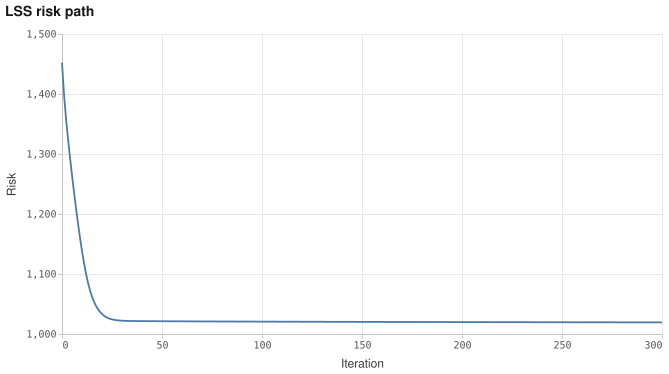

In [3]:
mb.plot.plot_lss_risk(m)

## Prediction per distribution parameter

Use `predict(parameter=...)` for one parameter, or `predict_all()` for a table
of all parameters.

In [4]:
m.predict_all(output="auto").head()

index,y,mu,sigma
0,6.682917,4.240557,2.289857
1,2.803055,1.143129,1.234337
2,1.942713,4.61479,2.325067
3,-2.86095,-2.353169,0.698433
4,0.20051,2.011434,1.468492


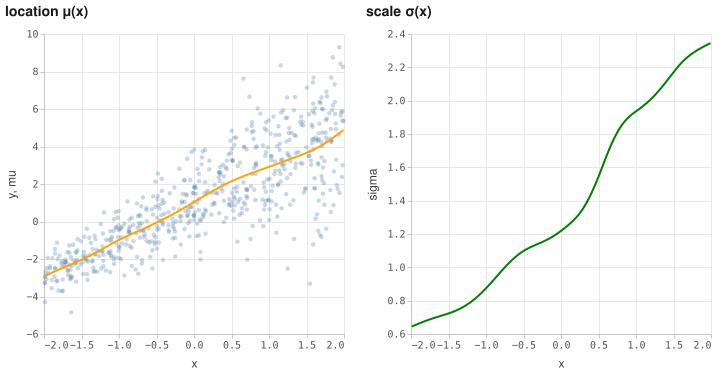

In [5]:
mu_hat = m.predict(parameter="mu", type="response")
sigma_hat = m.predict(parameter="sigma", type="response")
o = np.argsort(x)
import polars as pl
import altair as alt
pdf_mu = pl.DataFrame({"x": x, "y": y, "mu": mu_hat})
pts = alt.Chart(pdf_mu).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
mu_line = alt.Chart(pl.DataFrame({"x": x[o], "mu": mu_hat[o]})).mark_line(color="orange").encode(x="x", y="mu")
c1 = (pts + mu_line).properties(title="location  μ(x)")
c2 = alt.Chart(pl.DataFrame({"x": x[o], "sigma": sigma_hat[o]})).mark_line(color="green").encode(
    x="x", y=alt.Y("sigma", scale=alt.Scale(zero=False))
).properties(title="scale  σ(x)")
alt.hconcat(c1, c2)

### The `mu` parameter and the response mean

For `GaussianLSS`, the location parameter is the conditional response mean, so
`predict(parameter="mu")` returns the mean. For other families, `mu` need not
be the response mean:

- `LogNormalLSS` puts `mu` on the log scale, so its mean is
  `exp(mu + sigma**2 / 2)`.
- `WeibullLSS` and `LogLogLSS` have means that multiply the location by a
  gamma-function or trigonometric factor of the shape parameter.
- The zero-adjusted families multiply the mean of the positive part by the
  probability of a non-zero response.
- `BCCGLSS` has `mu` as the *median*.
- `StudentTLSS` has no finite mean when `df <= 1`.

`family.mean(params)`
returns the conditional response mean on the response scale, and refuses,
naming the reason, for a family whose mean is undefined for those parameters
or is not implemented:


In [6]:
for fam, params in [
    (mb.GaussianLSS(), {"mu": np.array([2.0]), "sigma": np.array([0.5])}),
    (mb.LogNormalLSS(), {"mu": np.array([2.0]), "sigma": np.array([0.5])}),
    (mb.WeibullLSS(), {"mu": np.array([2.0]), "sigma": np.array([0.5])}),
]:
    print(f"{type(fam).__name__:16s} mu=2.0 -> mean {float(fam.mean(params)[0]):.4f}")

for fam, params in [
    (mb.StudentTLSS(), {"mu": np.array([0.0]), "sigma": np.array([1.0]),
                        "df": np.array([0.8])}),
    (mb.BCTLSS(), {"mu": np.array([2.0]), "sigma": np.array([0.3]),
                   "nu": np.array([0.5]), "tau": np.array([5.0])}),
]:
    try:
        fam.mean(params)
    except (ValueError, NotImplementedError) as refusal:
        print(f"{type(fam).__name__:16s} refused: {refusal}")


GaussianLSS      mu=2.0 -> mean 2.0000
LogNormalLSS     mu=2.0 -> mean 8.3729
WeibullLSS       mu=2.0 -> mean 6.5484
StudentTLSS      refused: StudentTLSS has no finite mean where df <= 1
BCTLSS           refused: BCTLSS mu is a location parameter; the truncated Box-Cox-t response mean is not implemented


In R the same accessor is `lss_mean(family, params)`, with the same refusals.


The scale prediction increases with `x`: the variance of the response is not
constant (heteroscedasticity), which a mean-only model would treat as noise.

## Visualizing the fit

`plot_lss` plots the partial effects of each distribution parameter's linear predictor. For a `gamboostLSS` parameter it draws one curve per selected learner (each learner's contribution on the link scale); for a `glmboostLSS` parameter it draws the accumulated coefficient times each predictor, with a rug of the observed values. A parameter fitted without named predictors is plotted as its linear predictor against observation index:

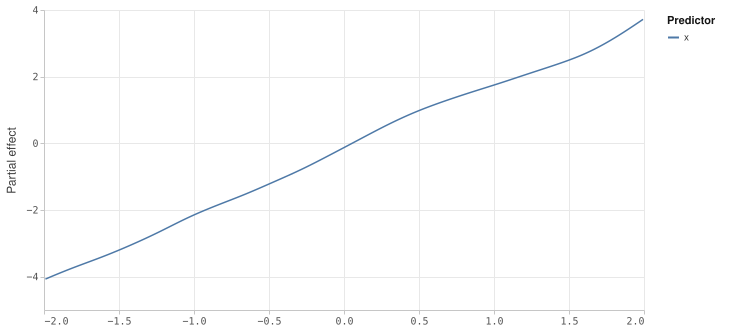

In [7]:
mb.plot.plot_lss(m, parameter="mu")


`plot_lss_risk` draws the combined risk path:

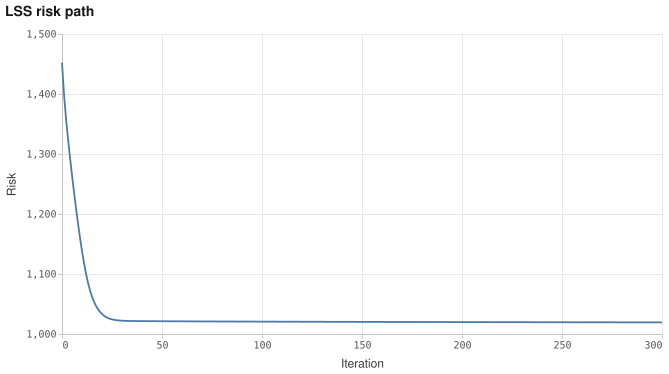

In [8]:
mb.plot.plot_lss_risk(m)


See [](plotting_serialization.ipynb) for all plotting functions.

## Per-parameter formulas

Pass a regular formula (same for all parameters) or a dict for asymmetric
models, where each parameter has different predictors. A string or
categorical column is encoded as in the standard models: in `glmboostLSS` a
bare factor term becomes treatment-contrast columns (`gb`, `gc` for levels
`a < b < c`), and in `gamboostLSS` `bols(g)` fits one effect per level and
`brandom(g)` a penalized one. `gamboostLSS` fits a factor `by=` as
`gamboost` does, with one copy of the learner's design per non-reference
level, in Python and in R; `glmboostLSS` refuses it. An asymmetric model:

In [9]:
n = 600
x1 = rng.uniform(0, 1, n)
x2 = rng.uniform(0, 1, n)
y_lss = 1.0 + 2.0 * x1 + rng.normal(scale=np.exp(0.5 + x2), size=n)
m_asy = gamboostLSS(
    {"mu": "y ~ bbs(x1, df=4) + bbs(x2, df=4)", "sigma": "y ~ bbs(x2, df=4)"},
    data={"x1": x1, "x2": x2, "y": y_lss},
    family=GaussianLSS(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
for param in m_asy.param_names:
    coefs = m_asy.coef(parameter=param)
    print(f"{param} selected: {list(coefs.keys())}")

mu selected: ['x1', 'x2', '(offset)']
sigma selected: ['x2', '(offset)']


Here only `x2` enters the scale model, while both predictors appear in the
location model. A parameter formula may mix `bols`, `bbs`, `bns`, `brandom`,
`bmrf`, `bspatial`, `bmono`, `bconstrained`, `btree`, `bkernel`, and `buser`. `bspatial(x1, x2, ...)` is one candidate learner, not
two marginal smooths: it fits a tensor-product surface whose additive penalty
controls roughness along both coordinate axes. Its coefficient block is selected
as a unit. New-data prediction must supply both coordinate columns and reuses the
training boundary knots. Partial effects therefore return coordinate pairs and one
surface effect per row.

`bmono(x, constraint=...)` is a shape-constrained
spline candidate. Its constraint applies to every coefficient increment, so
their aggregated partial effect retains the requested shape. The default `quad.prog` solver, a quadratic-programming solver, solves the
constrained least-squares problem of each step exactly; `type="iterative"` approximates it and
is faster, at the cost of a violation that a long path accumulates.

`bconstrained(x, C=C_shape, ...)` generalizes the same spline to an arbitrary
linear condition $C\beta \ge 0$. For `knots=k` and degree `d`, `C` must
have `k + d + 1` columns. Bind the matrix name through `env` in Python or
define it in the R formula environment.

`btree(x, z, maxdepth=2)` lets one
Python learner search both columns for splits. Each selected update stores a
complete encoded tree, so coefficient inspection returns a list of node vectors
rather than adding incompatible tree topologies. The R formula frontend
accepts one splitting variable per `btree` term.

`buser(custom, X=X_custom, K=K_custom)` stores a caller-defined training design and penalty; fitting and link prediction agree with R mboost's `buser`. CV and stability selection keep its rows fixed and alter observation weights; new-data operations require `buser_newdata={"custom": X_new}` in Python or `list(custom=X_new)` in R.

`bkernel(x, ...)` fits a kernel ridge regression in one covariate: its design is the $n \times n$ matrix of kernel values $k(|x_i - x_j| / h)$ between the training rows (Gaussian kernel and bandwidth $h = 1$ by default), and a new row is evaluated through its kernel values against the training rows. The R `bkernel` learner used for pathway analysis of genome-wide association data builds its kernel from many variables at once (the genetic markers of a pathway), so coefficients and fits of the two learners cannot be compared.

## Extracting coefficients per parameter

For reporting, `coef_all(output="polars")` returns one row per parameter and learner. A spline coefficient is a vector, so the compact summary below reports its length and Euclidean norm instead of printing every basis coefficient.

In [10]:
coef_table = m.coef_all(output="polars")
pl.DataFrame([
    {
        "parameter": row["parameter"],
        "learner": row["learner"],
        "n_coefficients": int(np.asarray(row["coefficient"]).size),
        "l2_norm": float(np.linalg.norm(np.asarray(row["coefficient"]))),
    }
    for row in coef_table.iter_rows(named=True)
])

parameter,learner,n_coefficients,l2_norm
"""mu""","""x""",24,12.61314
"""mu""","""(offset)""",1,1.162817
"""sigma""","""x""",24,4.37415
"""sigma""","""(offset)""",1,1.002233


In [11]:
for param in m.param_names:
    c = m.coef(parameter=param)
    print(f"{param}: {c}")

mu: {'x': array([-4.45484443, -4.0656576 , -3.717404  , -3.41242635, -3.05712763,
       -2.66459957, -2.21901488, -1.86345434, -1.54244784, -1.16513212,
       -0.79135245, -0.34869015,  0.10140869,  0.55601339,  0.95159502,
        1.26511582,  1.54654722,  1.80957776,  2.09869058,  2.37122864,
        2.68067601,  3.14469505,  3.71761538,  4.3023646 ]), '(offset)': 1.162817358789313}
sigma: {'x': array([-1.49829196, -1.44069938, -1.38616681, -1.34746926, -1.31242758,
       -1.25212767, -1.16205564, -1.05384872, -0.9569669 , -0.89692219,
       -0.86794511, -0.83139842, -0.77801429, -0.71445418, -0.58898426,
       -0.441397  , -0.3632803 , -0.33546766, -0.29905938, -0.2479449 ,
       -0.19587058, -0.16824779, -0.14955388, -0.1324604 ]), '(offset)': 1.0022328861739307}


## LSS cross-validation

For the linear case (`glmboostLSS`) you can tune `mstop` with cross-validation:

In [12]:
n = data["x"].shape[0]
folds = mb.cv_weights(n, type="kfold", B=10, seed=0)
grid = [(50, 50), (100, 100), (200, 200)]
cv_lss = mb.cvrisk_glmboostLSS(
    "y ~ x", data=data, family=GaussianLSS(),
    control=mb.boost_control(300, 0.1),
    folds=folds, grid=grid,
)
print(f"CV-optimal LSS mstop: mu={cv_lss['mstop'][0]}, sigma={cv_lss['mstop'][1]}")

CV-optimal LSS mstop: mu=50, sigma=50


## Tuning additive GAMLSS models

For smooth models with `bbs` terms, `cvrisk_gamboostLSS` re-fits each fold from
scratch. The penalty that gives each term its requested degrees of freedom
(`df`) is recomputed from the fold's training rows, as in R gamboostLSS. Pass `folds` as an integer fold count (`folds=5`) or as a
matrix from `mb.cv_weights`:

In [13]:
cv_lss_smooth = mb.cvrisk_gamboostLSS(
    "y ~ bbs(x, df=4)",
    data=data,
    family=GaussianLSS(),
    control=mb.boost_control(400, 0.1),
    folds=folds,
    # one point past 200, where the linear model's search above stopped
    grid=grid + [(400, 400)],
)
print(f"CV-optimal smooth LSS mstop: mu={cv_lss_smooth['mstop'][0]}, sigma={cv_lss_smooth['mstop'][1]}")

CV-optimal smooth LSS mstop: mu=50, sigma=50


The grid search accepts every learner currently supported by `gamboostLSS`:
`bols`, `bbs`, `bns`, `brandom`, `bmrf`, `bspatial`, `bmono`, `bconstrained`, `btree`, `bkernel`, and `buser`. In each fold the
centering and the smoothing parameter implied by `df` are computed from that
fold's training rows only. For `buser` and `bkernel` the design keeps all rows,
and the fold weights select the training rows.

## Cyclic and non-cyclic fitting

`glmboostLSS`/`gamboostLSS` default to **cyclic** updates (every parameter is
updated each iteration). `method="noncyclic"` {cite}`thomas2018gradient` instead
updates only the single parameter that most reduces the risk per step, which
makes a single `mstop` tune all parameters jointly:

In [14]:
m_nc = glmboostLSS("y ~ x", data=data, family=GaussianLSS(),
                   control=mb.boost_control(mstop=300, nu=0.1),
                   method="noncyclic")
{name: len(path) for name, path in m_nc.selected.items()}

{'mu': 111, 'sigma': 189}

The step count of a non-cyclic fit is one number, the total over all
parameters; the fit decides how to divide it. `m_nc.cvrisk()` cross-validates
that total. A non-cyclic path is a prefix of any longer one, so each fold is
fitted once, to the largest total in the grid, and every smaller total is
read off it. The grid may extend past the model's own budget. Each grid point and `optimal_mstop` are one-element lists
holding a total, and `with_mstop` accepts that list directly; the refitted
model reports how the algorithm divided the total:

In [15]:
# totals beyond the fitted 300, so the search can see where the risk levels off
cv_nc = m_nc.cvrisk(grid=[25, 50, 100, 200, 400, 800], B=5, seed=1)
m_nc_tuned = m_nc.with_mstop(cv_nc.optimal_mstop)
{"optimal total": cv_nc.optimal_mstop[0], "allocation": m_nc_tuned.mstop}

{'optimal total': 100, 'allocation': {'mu': 30, 'sigma': 70}}

## Distributional diagnostics

An LSS model predicts a distribution and can therefore produce intervals and
randomized quantile residuals:

In [16]:
intervals = m.prediction_interval(level=0.9)
intervals.head()

index,lower,median,upper,level,lower_prob,upper_prob
0,0.474078,4.240557,8.007036,0.9,0.05,0.95
1,-0.887175,1.143129,3.173432,0.9,0.05,0.95
2,0.790395,4.61479,8.439184,0.9,0.05,0.95
3,-3.501989,-2.353169,-1.204349,0.9,0.05,0.95
4,-0.404021,2.011434,4.426888,0.9,0.05,0.95


In [17]:
rate, width = mb.coverage(data["y"], intervals["lower"], intervals["upper"])
print(f"90% interval empirical coverage: {rate:.3f}; average width: {width:.3f}")

90% interval empirical coverage: 0.903; average width: 4.731


In [18]:
m.residual_frame(kind="quantile").head()

index,y,residual_kind,residual,mu,sigma,pit,deviance
0,6.682917,"""quantile""",1.066599,4.240557,2.289857,0.856924,4.63249
1,2.803055,"""quantile""",1.344792,1.143129,1.234337,0.910654,4.06741
2,1.942713,"""quantile""",-1.149247,4.61479,2.325067,0.125227,4.846144
3,-2.86095,"""quantile""",-0.727028,-2.353169,0.698433,0.233604,1.648615
4,0.20051,"""quantile""",-1.233186,2.011434,1.468492,0.108753,4.127096


In [19]:
m.q_stats(xvar="x", n_intervals=6)

interval,xvar,x_min,x_max,n,mean,variance,skewness,kurtosis
1,"""x""",-1.990396,-1.223453,100,-0.007425,1.003275,-0.347713,0.676997
2,"""x""",-1.222186,-0.516185,100,-0.04183,1.016584,-0.130139,-0.443042
3,"""x""",-0.514561,0.119069,100,0.049707,1.104563,0.1307,-0.223992
4,"""x""",0.120466,0.818591,100,-0.005971,0.987653,0.253074,-0.066505
5,"""x""",0.819459,1.456784,100,0.057136,0.875417,-0.245992,0.152277
6,"""x""",1.46536,1.993652,100,-0.053026,1.062176,-0.446781,-0.09527


## Fitting one parameter with the others fixed

R's `gamboostLSS` provides a family per parameter — `GaussianMu()`,
`GaussianSigma()` — for fitting one distribution parameter while the others
stay fixed. `GaussianLSS()$mu` is `GaussianMu()`; they are the
components of the joint family.

mboostrs uses a per-parameter `mstop` value instead of a separate family object. A parameter whose `mstop` is `0` never takes a boosting
step, so it stays at its offset for the whole fit:

```python
# boost mu only; sigma stays at its offset
fit = mb.gamboostLSS(
    {"mu": "y ~ bbs(x, df=4)", "sigma": "y ~ bols(x)"},
    data=data, families=mb.GaussianLSS(),
    control=mb.boost_control(60, 0.1),
    mstop={"mu": 60, "sigma": 0},
)
```

To pin the held parameter at a chosen value rather than at the value the data
imply (which is what `GaussianMu(sigma = 1.5)` does), set its offset. Offsets
are on the link scale, so a log-linked `sigma` of 1.5 is `log(1.5)`:

```python
fit = mb.gamboostLSS(
    {"mu": "y ~ bbs(x, df=4)", "sigma": "y ~ bols(x)"},
    data=data, families=mb.GaussianLSS(),
    control=mb.boost_control(60, 0.1),
    mstop={"mu": 60, "sigma": 0},
    offset=[0.0, float(np.log(1.5))],
)
```

Either parameter can be the held one, and the same works in R through
`mstop = c(mu = 60, sigma = 0)`.


## Per-parameter step length: `nu`

`mstop` decides how many steps a parameter takes; `nu` decides how far each
step moves it. Setting `nu` per parameter separates the two, so a parameter
can take steps at a rate suited to its gradient scale.

Parameters converge at different rates. A scale or shape term sits behind a
non-linear link, so the same step length that is right for the mean can push
the scale much further along the response scale, and its risk curve then turns
long before the location's does. One shared `nu` forces a compromise: small
enough for the scale means the location needs many more iterations. A smaller
`nu` on the scale holds it back while the location fits at full pace.

The per-parameter rates are passed as the fit function's `nu=`;
`boost_control(nu = ...)` takes a single value. R gamboostLSS takes the same
rates as a vector in `boost_control(nu = c(...))`. Four spellings are
accepted:

| `nu=` | Meaning |
|---|---|
| `None` (default) | every parameter uses the control's scalar |
| `0.05` | every parameter uses this rate |
| `[0.1, 0.01]` | one rate per parameter, in `family.param_names` order |
| `{"mu": 0.1, "sigma": 0.01}` | named; every parameter must appear |

Each rate must satisfy `0 < nu <= 1`, as the scalar does. `cvrisk_*LSS` and `stabsel_*LSS` take `nu=` too (stability selection refits on random half-samples and keeps the terms chosen in most of them), so a rate chosen
here carries into cross-validation and stability selection instead of silently
reverting to the control's scalar.


In [20]:
slow_sigma = gamboostLSS(
    {"mu": "y ~ bbs(x1, df=4) + bbs(x2, df=4)", "sigma": "y ~ bbs(x2, df=4)"},
    data={"x1": x1, "x2": x2, "y": y_lss},
    family=GaussianLSS(),
    control=mb.boost_control(mstop=300, nu=0.1),
    nu={"mu": 0.1, "sigma": 0.01},
)
shared = np.asarray(m_asy.predict(parameter="sigma", type="response"))
held_back = np.asarray(slow_sigma.predict(parameter="sigma", type="response"))
mu_shared = np.asarray(m_asy.predict(parameter="mu", type="response"))
mu_held = np.asarray(slow_sigma.predict(parameter="mu", type="response"))
print(f"sigma spread, shared nu=0.1  : {shared.max() - shared.min():.4f}")
print(f"sigma spread, sigma nu=0.01  : {held_back.max() - held_back.min():.4f}")
print(f"mu range, shared nu=0.1      : {mu_shared.min():.3f} to {mu_shared.max():.3f}")
print(f"mu range, sigma held back    : {mu_held.min():.3f} to {mu_held.max():.3f}")


sigma spread, shared nu=0.1  : 3.4963
sigma spread, sigma nu=0.01  : 3.0209
mu range, shared nu=0.1      : 0.470 to 2.959
mu range, sigma held back    : 0.453 to 2.949


## Methods on a fitted LSS model

A fitted `LSSModel` carries the same operations as `glmboost` and `gamboost`
fits, answered per distribution parameter. They dispatch on the fitting
function that produced the model, so you never name it twice:

| Method | Returns |
|---|---|
| `.cvrisk(folds=..., grid=...)` | cross-validated risk over a grid of per-parameter `mstop` (a grid of totals for a non-cyclic fit) |
| `.stabsel(q=..., PFER=...)` | stability selection over the combined `learner.parameter` names |
| `.varimp()` | risk reduction per learner and parameter (needs `method="noncyclic"`) |
| `.continue_to(m)` | the model grown to a larger `mstop` |
| `.bnames()`, `.variable_names()`, `.selected_which()` | names, keyed by parameter |
| `.fitted_`, `.offset_`, `.control`, `.offset` | fitted values and settings, keyed by parameter |
| `.plot_risk()`, `.plot_selected()` | the joint risk path; selection frequency faceted by parameter |
| `.save(path)` | a portable JSON artifact |

The module-level `cvrisk_glmboostLSS` / `cvrisk_gamboostLSS` /
`stabsel_glmboostLSS` / `stabsel_gamboostLSS` remain, but the method forms are
preferred: they dispatch to the fitting function stored on the model,
so an LSS fit uses the corresponding LSS resampling procedure.

`varimp()` raises an error for a cyclic fit. A cyclic LSS records the joint
risk once per cycle, after every parameter has been updated, so there is no
per-update risk change to attribute — summing it anyway puts the whole cycle's
drop on whichever update happened to come last, and the dominant predictor can
score zero. Refit with `method="noncyclic"` for per-update attribution.

### Saving a distributional model

`LSSModel` writes the same portable JSON artifact the standard models do, so a
fitted distributional model can be archived next to a paper or moved to a
production service without pickling:

```python
fit.save("model.json")
reloaded = mb.load_model("model.json")
```

The round trip is exact — predictions, centiles, and the risk path all come back
bit-identical. Only the Python reader scores a distributional artifact; the R and
Rust readers refuse one by name at load time rather than misreading it.


### Example: semicontinuous data with `ZeroAdjustedGammaLSS`

In this family the third distribution parameter, named `nu`, is the probability
of a zero; it is unrelated to the step length `nu`. Here the probability of a
zero depends on the predictor, and the fit recovers that dependence:


In [21]:
rng_zaga = np.random.default_rng(9)
n_zaga = 500
x_zaga = rng_zaga.normal(size=n_zaga)

# semicontinuous: the zero probability and the positive mean both depend on x
p_zero = 1.0 / (1.0 + np.exp(-(-0.5 + 0.8 * x_zaga)))
is_zero = rng_zaga.random(n_zaga) < p_zero
y_zaga = np.where(is_zero, 0.0, rng_zaga.gamma(3.0, np.exp(0.4 + 0.3 * x_zaga) / 3.0))

m_zaga = mb.gamboostLSS(
    {"mu": "y ~ bbs(x, df=4)", "sigma": "y ~ bols(x)", "nu": "y ~ bbs(x, df=4)"},
    data={"x": x_zaga, "y": y_zaga},
    families=mb.ZeroAdjustedGammaLSS(),
    control=mb.boost_control(80, 0.1),
)
nu_hat = np.asarray(m_zaga.fitted(parameter="nu", type="response"))
print("observed zero rate:", round(float(is_zero.mean()), 3))
print("mean fitted P(zero):", round(float(nu_hat.mean()), 3))
print("correlation with the true zero probability:",
      round(float(np.corrcoef(nu_hat, p_zero)[0, 1]), 4))

observed zero rate: 0.374
mean fitted P(zero): 0.378
correlation with the true zero probability: 0.999


See [](diagnostics.ipynb) for the full diagnostic workflow.

## Available LSS families

Python and R export the same 27 families:

`GaussianLSS`, `GammaLSS`, `StudentTLSS`, `BetaLSS`, `NBinomialLSS`,
`NegativeBinomialLSS`, `PoissonLSS`, `GeometricLSS`, `BinomialLSS`,
`GumbelLSS`, `LogisticLSS`, `InverseGaussianLSS`, `Pareto2LSS`, `PIGLSS`,
`BCCGLSS`, `BCTLSS`, `BCPELSS`, `JSULSS`, `LogNormalLSS`, `LogLogLSS`, `WeibullLSS` (survival),
`GaussianKnownVarLSS` (Gaussian with a known per-observation variance),
`ZIPoLSS`, `ZINBLSS`, `ZeroAdjustedPoissonLSS`, `ZeroAdjustedGammaLSS`
(zero-inflated or zero-adjusted responses), and `DirichletLSS` (compositional).
`NBinomialLSS` and `NegativeBinomialLSS` describe the same negative-binomial
distribution with `sigma` on reciprocal scales: in `NBinomialLSS` (as in R
gamboostLSS) `sigma` is the size, with variance $\mu + \mu^2/\sigma$; in
`NegativeBinomialLSS` (the `NBI` parameterization of gamlss) `sigma` is the
dispersion, with variance $\mu + \sigma\mu^2$. A `sigma` predictor fitted
with one family is not interchangeable with the other. See [](../methodology/gamlss) for their parameterizations, links, and
the cases where mboostrs differs from R `gamboostLSS`.

Three of these families cover cases the others do not:

| Family | Response | Use it when |
|---|---|---|
| `InverseGaussianLSS` | $y > 0$ | right-skewed positive data whose variance grows as $\sigma^2\mu^3$ — faster with the mean than Gamma allows |
| `LogisticLSS` | $y \in \mathbb{R}$ | symmetric residuals that are mildly outlier-prone; heavier-tailed than Gaussian at the same scale |
| `ZeroAdjustedGammaLSS` | $y \ge 0$ | semicontinuous data — exact zeros plus a right-skewed positive part |

`ZeroAdjustedGammaLSS` fits responses such as insurance claims, daily rainfall
and household spend, which are positive and skewed for nonzero observations and
exactly zero otherwise. Its third parameter, named `nu` (unrelated to the step length), is the
probability of a zero,
on a logit link, so learners can model that probability separately from the
mean of the positive component. Fitting a Gamma after dropping zeros models
only the positive component.

```{note}
`GumbelLSS` matches `gamlss.dist::RG()` — what gamlss calls "Reverse Gumbel",
and commonly called the Gumbel: the right-skewed
extreme-value distribution for maxima. gamlss's naming inverts the common one,
so its `GU()` is the Gumbel for *minima* and is not implemented here.
```

`DirichletLSS` supports compositions of 2 to 20 components (`K`).

## LSS models in R

The R binding supports `gamboostLSS` and `glmboostLSS` with the same family
objects:

```r
library(mboostrs)
set.seed(4)
n <- 600
x <- runif(n, -2, 2)
mu_true <- 1.0 + 2.0 * x
sigma_true <- exp(0.2 + 0.4 * x)
y <- mu_true + sigma_true * rnorm(n)
data <- data.frame(x, y)

# gamboostLSS
m <- gamboostLSS(y ~ bbs(x, df = 4), data = data, families = GaussianLSS(),
                 control = boost_control(300, 0.1))

# glmboostLSS (linear)
m_lin <- glmboostLSS(y ~ x, data = data, families = GaussianLSS(),
                     control = boost_control(300, 0.1))

# Predict per parameter
mu_hat <- predict(m, parameter = "mu", type = "response")
sigma_hat <- predict(m, parameter = "sigma", type = "response")
```

The R frontend carries the same 27 families as Python, including
`LogisticLSS`, `InverseGaussianLSS`, and `ZeroAdjustedGammaLSS`. Every listed family fits and predicts in both frontends.

The R frontend covers the same ground: fitting, in-sample and new-data
prediction, LSS plotting (`plot_lss`, `plot_lss_risk`, `plot_lss_cvrisk`), and
`cvrisk_glmboostLSS`/`cvrisk_gamboostLSS`.

```{note}
In Python, per-parameter `mstop` is supported with a dict such as
`mstop={"mu": 200, "sigma": 50}`. In R, use named values such as
`mstop = c(mu = 200, sigma = 50)` where supported. Tune the grid with
`cvrisk_glmboostLSS` or `cvrisk_gamboostLSS`.
```


## REML refit: `gamlss_refit`

A boosted distributional model stopped early shrinks every parameter's
effects, and its smoothness is set by the stopping iterations. After boosting
has chosen each parameter's terms, `mb.gamlss_refit(fit)` (R:
`gamlss_refit(fit)`) refits all parameters' terms jointly by penalized
likelihood with smoothing parameters estimated by the Laplace-approximate
restricted maximum likelihood (REML) criterion, and returns effects with pointwise
intervals and predictions for each parameter. The workflow is in
[](refit.ipynb) and the method in [](../methodology/gamlss_reml.ipynb).

## Comparative studies

The [Munich rents distributional study](../cases/munich_rents_distributional.ipynb) works through grouped validation, interpretation and save/load prediction checks. The [distributional comparison](../cases/distributional_comparison.ipynb) evaluates mboostrs against gamboostLSS, mssm and NGBoost.

## See also

- [](../implementation/lss_engine) — the multi-predictor Rust engine that powers `gamboostLSS`.
- [](../methodology/gamlss) — the GAMLSS parametrizations for all distributional families.
- [](../methodology/gamlss_framework) — the joint modeling of location, scale, and shape parameters.